# Predictive Analytics Using Historical Data

**Objective:** Use historical monthly sales data to train a regression model, evaluate it, visualize predictions, and forecast the next six months.

**Note:** `historical_sales.csv` is a synthetic example dataset created for learning. Replace it with real historical data if your instructor/platform requires real-world data.

Run the cells from top to bottom. If needed, install packages with `pip install pandas numpy matplotlib scikit-learn`.

In [2]:
%pip install pandas numpy matplotlib scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [4]:
import os

print("Current folder:", os.getcwd())
print("Files in folder:", os.listdir())

Current folder: C:\Users\HP
Files in folder: ['.anaconda', '.antigravity', '.bash_history', '.blip-device-dedupe-id', '.cache', '.conda', '.condarc', '.continuum', '.copilot', '.cursor', '.gemini', '.gitconfig', '.idlerc', '.ipynb_checkpoints', '.ipython', '.jupyter', '.keras', '.local', '.matplotlib', '.ollama', '.skiko', '.spyder-py3', '.venv', '.VirtualBox', '.vscode', '.vscode-shared', '2026-09-25-10-34-59.006-VirtualBoxVM.exe-8456.log', '2026-09-26-08-15-07.036-VirtualBoxVM.exe-10896.log', 'anaconda3', 'anaconda_projects', 'antigravity aws', 'AppData', 'Application Data', 'best_model.keras', 'chroma_db', 'Classify Waste Products.ipynb', 'Comparison of Memory-Based and Generator-Based Data Loading.ipynb', 'Contacts', 'Cookies', 'coursera.ipynb', 'CrossDevice', 'data', 'DataScienceEcosystem.ipynb', 'Documents', 'Downloads', 'Fashion MNIST Classification.ipynb', 'Favorites', 'fghjk.ipynb', 'Final project.ipynb', 'IdeaProjects', 'images-dataSAT.tar', 'images_dataSAT', 'League of Legen

In [5]:
df = pd.read_csv(
    r"C:\Users\HP\Downloads\historical_sales.csv",
    parse_dates=["Date"]
)

print(df.head())

        Date   Sales
0 2022-01-01  103.66
1 2022-02-01  104.52
2 2022-03-01  140.59
3 2022-04-01  153.29
4 2022-05-01  124.18


In [6]:
# Predictive Analytics Using Historical Data
# This project forecasts monthly sales using historical observations.

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 1. Load the dataset
df = pd.read_csv("historical_sales.csv", parse_dates=["Date"])
df = df.sort_values("Date").drop_duplicates()
df["Sales"] = pd.to_numeric(df["Sales"], errors="coerce")
df = df.dropna(subset=["Date", "Sales"]).reset_index(drop=True)

print("Dataset shape:", df.shape)
display(df.head())
print("\nMissing values:\n", df.isnull().sum())

# 2. Explore and visualize historical data
plt.figure(figsize=(10, 5))
plt.plot(df["Date"], df["Sales"], marker="o", label="Historical sales")
plt.title("Historical Monthly Sales")
plt.xlabel("Date")
plt.ylabel("Sales (illustrative units)")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

# 3. Create time-based features
df["MonthIndex"] = np.arange(len(df))
df["Month"] = df["Date"].dt.month
df["Month_sin"] = np.sin(2 * np.pi * df["Month"] / 12)
df["Month_cos"] = np.cos(2 * np.pi * df["Month"] / 12)

features = ["MonthIndex", "Month_sin", "Month_cos"]
X = df[features]
y = df["Sales"]

# 4. Split chronologically: first 80% for training, last 20% for testing
split = int(len(df) * 0.8)
X_train, X_test = X.iloc[:split], X.iloc[split:]
y_train, y_test = y.iloc[:split], y.iloc[split:]
test_dates = df["Date"].iloc[split:]

# 5. Train a regression model
model = LinearRegression()
model.fit(X_train, y_train)
predictions = model.predict(X_test)

# 6. Evaluate the model
mae = mean_absolute_error(y_test, predictions)
rmse = np.sqrt(mean_squared_error(y_test, predictions))
r2 = r2_score(y_test, predictions)

print(f"Mean Absolute Error (MAE): {mae:.2f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.2f}")
print(f"R-squared (R²): {r2:.3f}")

results = pd.DataFrame({
    "Date": test_dates.values,
    "Actual_Sales": y_test.values.round(2),
    "Predicted_Sales": predictions.round(2)
})
display(results)

# 7. Visualize actual versus predicted test values
plt.figure(figsize=(10, 5))
plt.plot(test_dates, y_test, marker="o", label="Actual sales")
plt.plot(test_dates, predictions, marker="x", linestyle="--", label="Predicted sales")
plt.title("Actual vs Predicted Sales (Test Period)")
plt.xlabel("Date")
plt.ylabel("Sales (illustrative units)")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

# 8. Forecast the next 6 months
last_date = df["Date"].max()
future_dates = pd.date_range(last_date + pd.offsets.MonthBegin(1), periods=6, freq="MS")
future_index = np.arange(len(df), len(df) + 6)
future_month = future_dates.month
future_X = pd.DataFrame({
    "MonthIndex": future_index,
    "Month_sin": np.sin(2 * np.pi * future_month / 12),
    "Month_cos": np.cos(2 * np.pi * future_month / 12)
})
future_predictions = model.predict(future_X[features])
forecast = pd.DataFrame({
    "Date": future_dates,
    "Forecast_Sales": np.maximum(future_predictions, 0).round(2)
})
display(forecast)

plt.figure(figsize=(10, 5))
plt.plot(df["Date"], df["Sales"], marker="o", label="Historical sales")
plt.plot(forecast["Date"], forecast["Forecast_Sales"], marker="x", linestyle="--", label="6-month forecast")
plt.title("Historical Sales and Future Forecast")
plt.xlabel("Date")
plt.ylabel("Sales (illustrative units)")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

# 9. Save prediction outputs for submission
results.to_csv("test_predictions.csv", index=False)
forecast.to_csv("future_sales_forecast.csv", index=False)
print("Saved: test_predictions.csv and future_sales_forecast.csv")


FileNotFoundError: [Errno 2] No such file or directory: 'historical_sales.csv'

In [7]:
import os

print(os.path.exists(r"C:\Users\HP\Downloads\historical_sales.csv"))

True


In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

df = pd.read_csv(
    r"C:\Users\HP\Downloads\historical_sales.csv",
    parse_dates=["Date"]
)

df = df.sort_values("Date").drop_duplicates()
df["Sales"] = pd.to_numeric(df["Sales"], errors="coerce")
df = df.dropna(subset=["Date", "Sales"]).reset_index(drop=True)

print(df.head())
print("Total records:", len(df))

        Date   Sales
0 2022-01-01  103.66
1 2022-02-01  104.52
2 2022-03-01  140.59
3 2022-04-01  153.29
4 2022-05-01  124.18
Total records: 48


In [9]:
import os

folder = r"C:\Users\HP\Downloads"

for file in os.listdir(folder):
    if file.lower().endswith(".csv"):
        print(file)

Customer_Segmentation_Dataset.csv
historical_sales.csv
Internship Available Courses & Faculty List - Sheet1.csv
my_assessment_report.csv
sales.csv
weather_data.csv


In [10]:

# 1. Create time-based features
df["MonthIndex"] = np.arange(len(df))
df["Month"] = df["Date"].dt.month

df["Month_sin"] = np.sin(2 * np.pi * df["Month"] / 12)
df["Month_cos"] = np.cos(2 * np.pi * df["Month"] / 12)

features = ["MonthIndex", "Month_sin", "Month_cos"]
X = df[features]
y = df["Sales"]

# 2. Split chronologically: 80% training, 20% testing
split = int(len(df) * 0.8)

X_train, X_test = X.iloc[:split], X.iloc[split:]
y_train, y_test = y.iloc[:split], y.iloc[split:]
test_dates = df["Date"].iloc[split:]

# 3. Train the model
model = LinearRegression()
model.fit(X_train, y_train)

# 4. Predict test sales
predictions = model.predict(X_test)

# 5. Evaluate model performance
mae = mean_absolute_error(y_test, predictions)
rmse = np.sqrt(mean_squared_error(y_test, predictions))
r2 = r2_score(y_test, predictions)

print(f"MAE: {mae:.2f}")
print(f"RMSE: {rmse:.2f}")
print(f"R-squared (R²): {r2:.3f}")

# 6. Display actual versus predicted sales
results = pd.DataFrame({
    "Date": test_dates.values,
    "Actual_Sales": y_test.values.round(2),
    "Predicted_Sales": predictions.round(2)
})

display(results)


MAE: 5.07
RMSE: 6.41
R-squared (R²): 0.836


,Date,Actual_Sales,Predicted_Sales
0,2025-03-01,409.69,423.17
1,2025-04-01,437.81,432.97
2,2025-05-01,444.51,437.92
3,2025-06-01,443.52,438.88
4,2025-07-01,428.01,437.77
5,2025-08-01,437.79,437.05
6,2025-09-01,437.81,439.10
7,2025-10-01,444.62,445.54
8,2025-11-01,462.87,456.82
9,2025-12-01,469.68,472.10


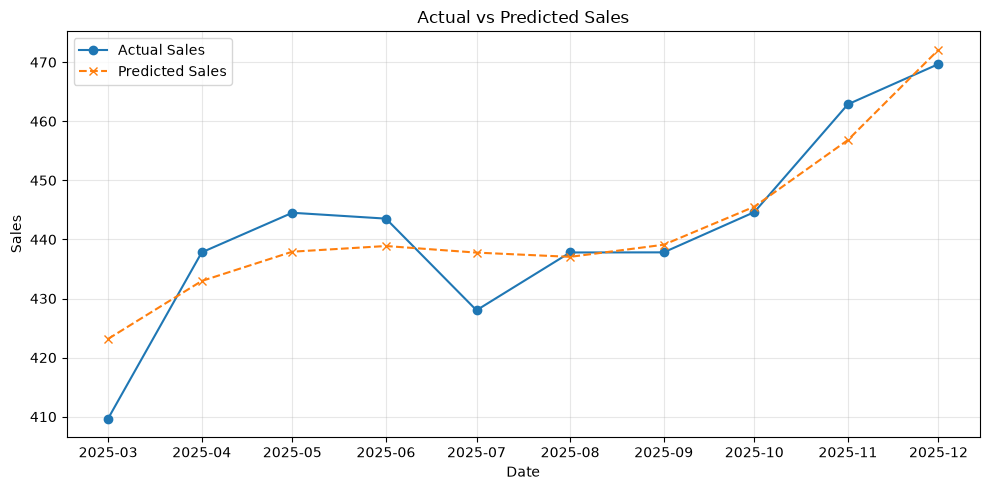

In [11]:

plt.figure(figsize=(10, 5))
plt.plot(test_dates, y_test, marker="o", label="Actual Sales")
plt.plot(
    test_dates, predictions,
    marker="x", linestyle="--", label="Predicted Sales"
)

plt.title("Actual vs Predicted Sales")
plt.xlabel("Date")
plt.ylabel("Sales")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


In [12]:

# Generate the next 6 months
last_date = df["Date"].max()

future_dates = pd.date_range(
    start=last_date + pd.offsets.MonthBegin(1),
    periods=6,
    freq="MS"
)

future_index = np.arange(len(df), len(df) + 6)
future_month = future_dates.month

# Create future features
future_X = pd.DataFrame({
    "MonthIndex": future_index,
    "Month_sin": np.sin(2 * np.pi * future_month / 12),
    "Month_cos": np.cos(2 * np.pi * future_month / 12)
})

# Predict future sales
future_predictions = model.predict(future_X[features])

forecast = pd.DataFrame({
    "Date": future_dates,
    "Forecast_Sales": np.maximum(future_predictions, 0).round(2)
})

display(forecast)


,Date,Forecast_Sales
0,2026-01-01,489.45
1,2026-02-01,506.40
2,2026-03-01,520.59
3,2026-04-01,530.39
4,2026-05-01,535.35
5,2026-06-01,536.31


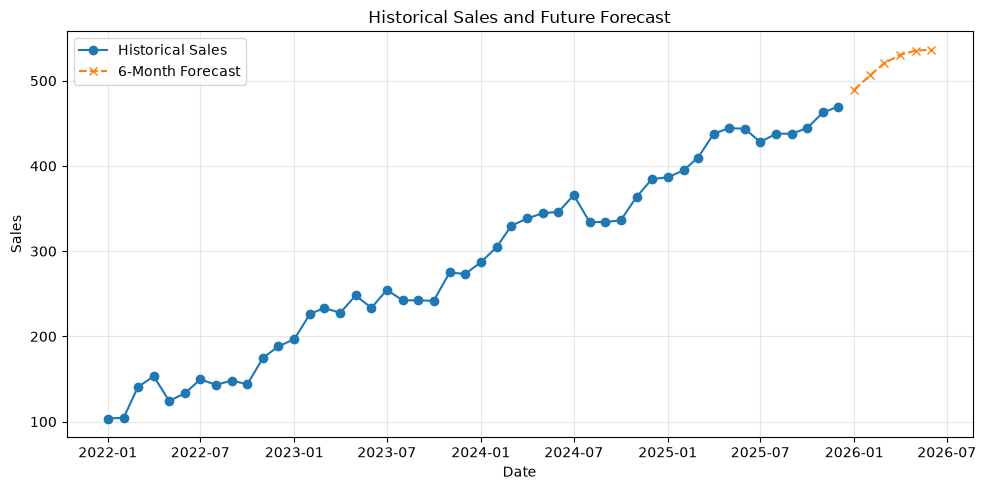

In [13]:

plt.figure(figsize=(10, 5))

plt.plot(
    df["Date"], df["Sales"],
    marker="o", label="Historical Sales"
)

plt.plot(
    forecast["Date"], forecast["Forecast_Sales"],
    marker="x", linestyle="--", label="6-Month Forecast"
)

plt.title("Historical Sales and Future Forecast")
plt.xlabel("Date")
plt.ylabel("Sales")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


In [14]:

results.to_csv(
    r"C:\Users\HP\Downloads\test_predictions.csv",
    index=False
)

forecast.to_csv(
    r"C:\Users\HP\Downloads\future_sales_forecast.csv",
    index=False
)

print("Both files saved successfully!")
print("1. test_predictions.csv")
print("2. future_sales_forecast.csv")


Both files saved successfully!
1. test_predictions.csv
2. future_sales_forecast.csv


In [15]:
import os

for filename in [
    "test_predictions.csv",
    "future_sales_forecast.csv"
]:
    path = os.path.join(r"C:\Users\HP\Downloads", filename)
    print(filename, "Exists:", os.path.exists(path))

test_predictions.csv Exists: True
future_sales_forecast.csv Exists: True
